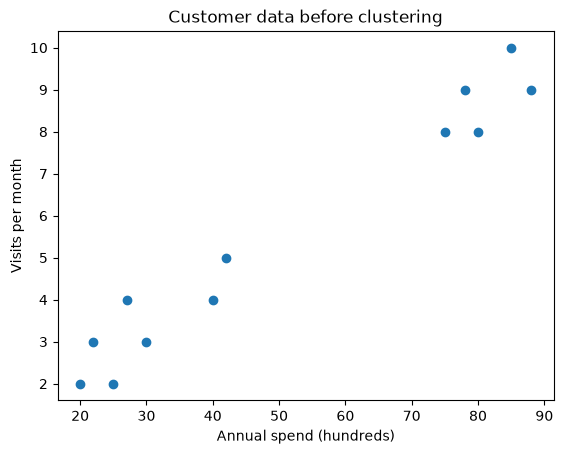

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

customers = pd.DataFrame({
    "AnnualSpend": [20,22,25,27,30,75,78,80,85,88,40,42],
    "VisitsPerMonth": [2,3,2,4,3,8,9,8,10,9,4,5]
})
plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"])
plt.xlabel("Annual spend (hundreds)")
plt.ylabel("Visits per month")
plt.title("Customer data before clustering")
plt.show()


C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


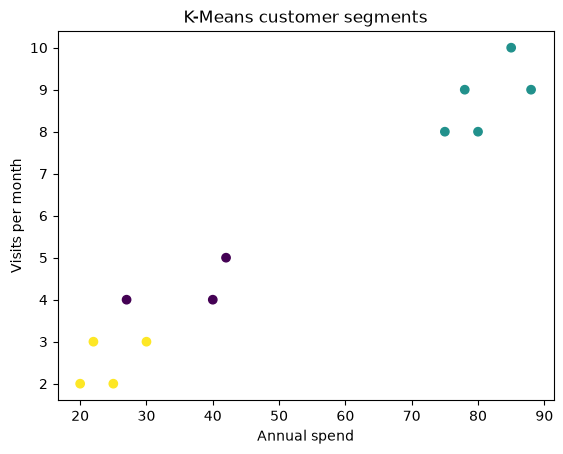

    AnnualSpend  VisitsPerMonth  Cluster
0            20               2        2
1            22               3        2
2            25               2        2
3            27               4        0
4            30               3        2
5            75               8        1
6            78               9        1
7            80               8        1
8            85              10        1
9            88               9        1
10           40               4        0
11           42               5        0


In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

scaler = StandardScaler()
X_scaled = scaler.fit_transform(customers)

km = KMeans(n_clusters=3, random_state=42, n_init=10)
customers["Cluster"] = km.fit_predict(X_scaled)

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=customers["Cluster"])
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("K-Means customer segments")
plt.show()
print(customers)

In [4]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

for k in range(2, 6):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    print(k,
          "inertia:", round(model.inertia_, 2),
          "silhouette:", round(silhouette_score(X_scaled, labels), 3))


C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


2 inertia: 2.03 silhouette: 0.786
3 inertia: 0.97 silhouette: 0.591
4 inertia: 0.66 silhouette: 0.449
5 inertia: 0.38 silhouette: 0.4


C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Cluster labels: [0 0 0 0 0 1 1 1 1 1 0 0]
Noise points: 0


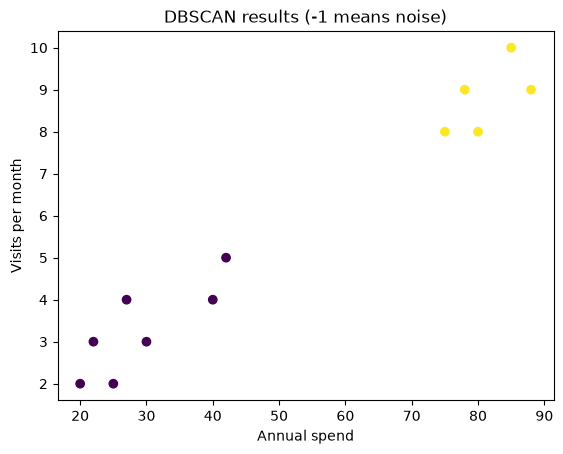

In [7]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=0.8, min_samples=2)
db_labels = db.fit_predict(X_scaled)

print("Cluster labels:", db_labels)
print("Noise points:", sum(db_labels == -1))

plt.scatter(customers["AnnualSpend"],
            customers["VisitsPerMonth"],
            c=db_labels)
plt.xlabel("Annual spend")
plt.ylabel("Visits per month")
plt.title("DBSCAN results (-1 means noise)")
plt.show()


Explained variance: [0.73  0.229]


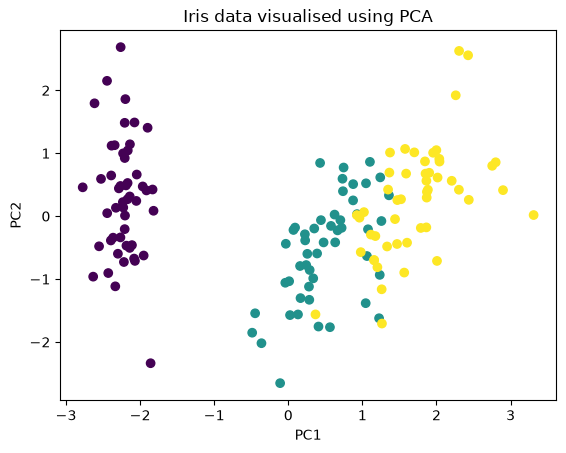

In [8]:
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

iris = load_iris()
X_iris = StandardScaler().fit_transform(iris.data)

pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_iris)

print("Explained variance:",
      pca.explained_variance_ratio_.round(3))
plt.scatter(X_2d[:,0], X_2d[:,1], c=iris.target)
plt.xlabel("PC1"); plt.ylabel("PC2")
plt.title("Iris data visualised using PCA")
plt.show()


In [9]:
from sklearn.ensemble import IsolationForest
import numpy as np

transactions = np.array([
    [20, 2], [22, 3], [18, 2], [25, 3],
    [21, 2], [23, 4], [19, 3], [250, 20]
])

detector = IsolationForest(contamination=0.12, random_state=42)
labels = detector.fit_predict(transactions)

for row, label in zip(transactions, labels):
    print(row, "Anomaly" if label == -1 else "Normal")


[20  2] Normal
[22  3] Normal
[18  2] Normal
[25  3] Normal
[21  2] Normal
[23  4] Normal
[19  3] Normal
[250  20] Anomaly


Customer Dataset:
    Customer  Annual_Spending  Visits_Per_Month
0          1            20000                 2
1          2            22000                 3
2          3            25000                 2
3          4            21000                 4
4          5            24000                 3
5          6            50000                 7
6          7            55000                 8
7          8            52000                 7
8          9            58000                 9
9         10            54000                 8
10        11            80000                12
11        12            85000                13
12        13            90000                14
13        14            82000                12
14        15            88000                13


C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



K-Means Clustering:
    Customer  Annual_Spending  Visits_Per_Month  Cluster
0          1            20000                 2        2
1          2            22000                 3        2
2          3            25000                 2        2
3          4            21000                 4        2
4          5            24000                 3        2
5          6            50000                 7        0
6          7            55000                 8        0
7          8            52000                 7        0
8          9            58000                 9        0
9         10            54000                 8        0
10        11            80000                12        1
11        12            85000                13        1
12        13            90000                14        1
13        14            82000                12        1
14        15            88000                13        1


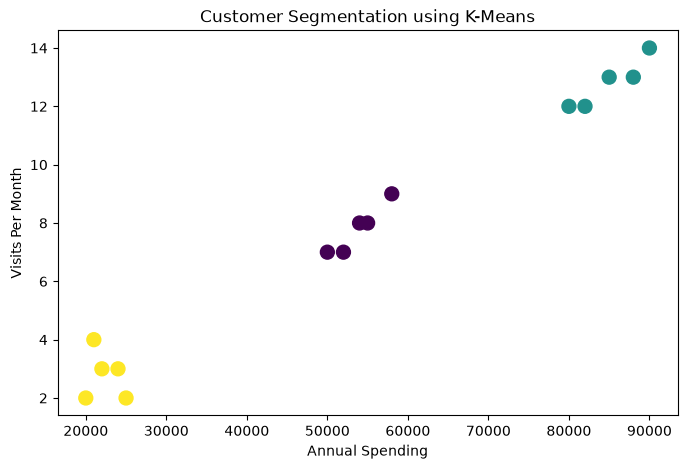


Average Spending of Each Cluster:
Cluster
0    53800.0
1    85000.0
2    22400.0
Name: Annual_Spending, dtype: float64


C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\Sakthi\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



Elbow and Silhouette Score Comparison:
   K Value   Inertia  Silhouette Score
0        2  7.980442          0.643386
1        3  0.672112          0.817169
2        4  0.467619          0.734474

Silhouette Scores:
K=2: 0.6433860339215461
K=3: 0.817168841967851
K=4: 0.7344739501779957


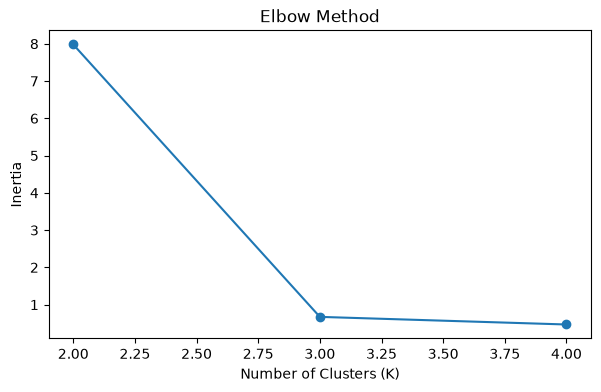

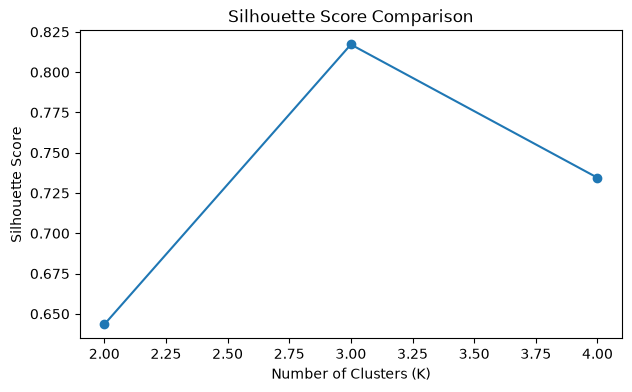


DBSCAN Clustering:
    Customer  DBSCAN_Cluster
0          1               0
1          2               0
2          3               0
3          4               0
4          5               0
5          6               1
6          7               1
7          8               1
8          9               1
9         10               1
10        11               2
11        12               2
12        13               2
13        14               2
14        15               2


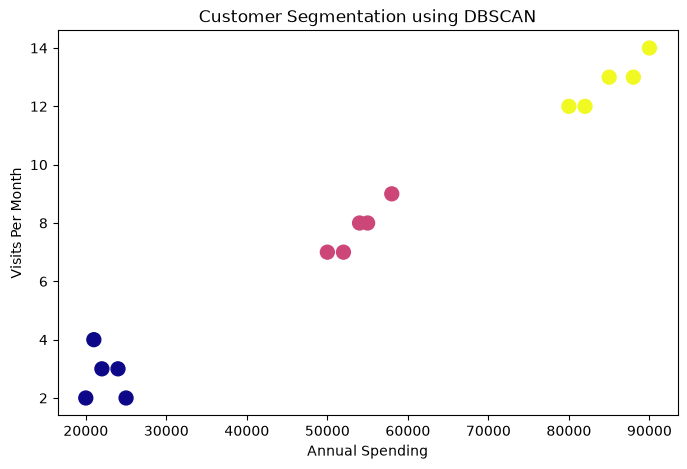


Customer Segment Descriptions:

Cluster 0
Average Spending: 53800.0
Average Visits: 7.8

Cluster 1
Average Spending: 85000.0
Average Visits: 12.8

Cluster 2
Average Spending: 22400.0
Average Visits: 2.8

-1 label in DBSCAN represents noise or outliers.


In [10]:
# Customer Segmentation using Clustering

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# Step 1: Create Customer Dataset

data = {
    'Customer': range(1, 16),
    'Annual_Spending': [
        20000, 22000, 25000, 21000, 24000,
        50000, 55000, 52000, 58000, 54000,
        80000, 85000, 90000, 82000, 88000
    ],
    'Visits_Per_Month': [
        2, 3, 2, 4, 3,
        7, 8, 7, 9, 8,
        12, 13, 14, 12, 13
    ]
}

df = pd.DataFrame(data)

print("Customer Dataset:")
print(df)

# Step 2: Scale Features

X = df[['Annual_Spending', 'Visits_Per_Month']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 3: Apply K-Means (K=3)

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("\nK-Means Clustering:")
print(df)

# Step 4: Visualize Clusters

plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Spending'],
    df['Visits_Per_Month'],
    c=df['Cluster'],
    cmap='viridis',
    s=100
)

plt.xlabel('Annual Spending')
plt.ylabel('Visits Per Month')
plt.title('Customer Segmentation using K-Means')
plt.show()

# Step 5: Average Spending

print("\nAverage Spending of Each Cluster:")
print(df.groupby('Cluster')['Annual_Spending'].mean())

# Step 6: Elbow and Silhouette Score

inertia = []
silhouette = []

for k in range(2, 5):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = model.fit_predict(X_scaled)

    inertia.append(model.inertia_)

    silhouette.append(silhouette_score(X_scaled, labels))

results = pd.DataFrame({
    'K Value': [2, 3, 4],
    'Inertia': inertia,
    'Silhouette Score': silhouette
})

print("\nElbow and Silhouette Score Comparison:")
print(results)

# Display Individual Scores

print("\nSilhouette Scores:")
print("K=2:", silhouette[0])
print("K=3:", silhouette[1])
print("K=4:", silhouette[2])

# Elbow Graph

plt.figure(figsize=(7, 4))
plt.plot([2, 3, 4], inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

# Silhouette Graph

plt.figure(figsize=(7, 4))
plt.plot([2, 3, 4], silhouette, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Comparison')
plt.show()

# Step 7: DBSCAN

dbscan = DBSCAN(eps=0.8, min_samples=2)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print("\nDBSCAN Clustering:")
print(df[['Customer', 'DBSCAN_Cluster']])

# DBSCAN Graph

plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Spending'],
    df['Visits_Per_Month'],
    c=df['DBSCAN_Cluster'],
    cmap='plasma',
    s=100
)

plt.xlabel('Annual Spending')
plt.ylabel('Visits Per Month')
plt.title('Customer Segmentation using DBSCAN')
plt.show()

# Step 8: Customer Segment Descriptions

print("\nCustomer Segment Descriptions:")

for cluster in sorted(df['Cluster'].unique()):
    group = df[df['Cluster'] == cluster]

    print("\nCluster", cluster)
    print("Average Spending:", group['Annual_Spending'].mean())
    print("Average Visits:", group['Visits_Per_Month'].mean())

print("\n-1 label in DBSCAN represents noise or outliers.")